MODELADO

In [1]:
import os
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

I0000 00:00:1795589891.657277  380978 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795589891.770036  380978 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795589895.490481  380978 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Establecemos una semilla aleatoria común para garantizar la reproducibilidad de los experimentos y configura la estética de los gráficos.

In [2]:
# Reproducibilidad global
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED) 
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")

Esto define una semilla que sirve como punto de partida para generar números pseudoaleatorios. El número 42 es arbitrario; podría utilizarse cualquier otro entero válido. En Machine Learning, esto permite reducir las diferencias entre ejecuciones al realizar particiones, inicializar pesos y entrenar modelos, facilitando una comparación reproducible.

RUTAS:

In [3]:
# Resolución de rutas (funciona desde raíz o desde /notebooks)
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT_DIR / "data" / "processed"
MODELS_DIR = ROOT_DIR / "models"
FIGURES_DIR = ROOT_DIR / "reports" / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Verificación de TensorFlow y aceleración disponible
gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow: {tf.__version__} | GPUs detectadas: {len(gpus)}")
print(f"Directorio raíz: {ROOT_DIR}")

TensorFlow: 2.21.0 | GPUs detectadas: 0
Directorio raíz: /home/matias-muller/Documents/Programacion/tp-ia-driving-behavior


E0000 00:00:1795589895.974730  380978 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:
# Cargamos datasets generados en el Notebook 2
kaggle_train = pd.read_parquet(DATA_DIR / "kaggle_train.parquet")
kaggle_test = pd.read_parquet(DATA_DIR / "kaggle_test.parquet")
github_df = pd.read_parquet(DATA_DIR / "github_events_features.parquet")

In [6]:
# Probamos una auditoría rápida de integridad (shapes, nulos, tipo de target y clases)
print("\nAuditoría de Datasets")
for nombre, df, col_target in [
    ("Kaggle Train", kaggle_train, "Target"),
    ("Kaggle Test", kaggle_test, "Target"),
    ("GitHub Events", github_df, "target"),
]:
    nulos = int(df.isna().sum().sum())
    print(f"\n{nombre}: shape={df.shape} | nulos={nulos} | target_dtype={df[col_target].dtype}")
    print(df[col_target].value_counts().sort_index().to_string())


Auditoría de Datasets

Kaggle Train: shape=(705, 43) | nulos=0 | target_dtype=int64
Target
1    158
2    183
3    226
4    138

Kaggle Test: shape=(305, 43) | nulos=0 | target_dtype=int64
Target
1    68
2    79
3    98
4    60

GitHub Events: shape=(69, 18) | nulos=0 | target_dtype=object
target
aceleracao_agressiva              12
curva_direita_agressiva           11
curva_esquerda_agressiva          11
evento_nao_agressivo              14
freada_agressiva                  12
troca_faixa_direita_agressiva      5
troca_faixa_esquerda_agressiva     4


----------------------------------------------------------------------------------------------------------------------------------------------

BLOQUE A: KAGGLE

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder

Procedemos con: Split X/y, codificación de clases y helper de evaluación CV

Utilizamos fit_transform() únicamente en entrenamiento y transform() en prueba para asegurar que ambos conjuntos compartan exactamente la misma codificación.

In [8]:
# Separación de features y target (kaggle_test queda guardado para la evaluación final)
feature_cols_k = [c for c in kaggle_train.columns if c != "Target"]

# Preparación de datos para modelado
X_k_train = kaggle_train[feature_cols_k].copy()
X_k_test = kaggle_test[feature_cols_k].copy()

# Codificación de etiquetas (Label Encoding) para el target
le_kaggle = LabelEncoder()

# fit_transform en el conjunto de entrenamiento y transform en el conjunto de prueba
y_k_train = le_kaggle.fit_transform(kaggle_train["Target"]) 
y_k_test = le_kaggle.transform(kaggle_test["Target"])

Configuramos una validación cruzada estratificada de 5 folds, sin mezclar aleatoriamente las observaciones. n_splits=5: divide el conjunto en cinco particiones. En cada iteración, utiliza aproximadamente el 80 % para entrenar y el 20 % para validar.
StratifiedKFold: mantiene aproximadamente la proporción original de las cuatro clases en cada partición.
shuffle=False: respeta el orden original de las observaciones dentro de cada clase al asignarlas a los folds.

In [9]:
# Validación cruzada estratificada SIN shuffle para respetar la contigüidad temporal
cv_kaggle = StratifiedKFold(n_splits=5, shuffle=False)

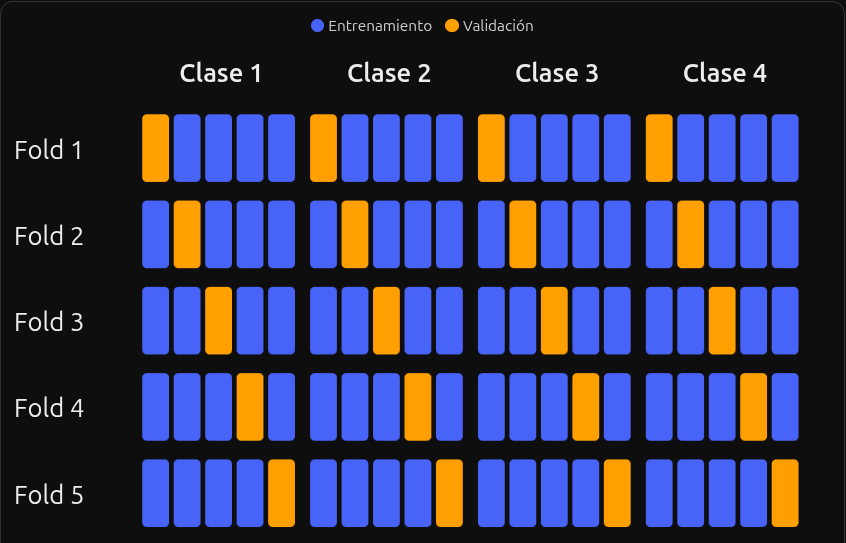

In [10]:
# Métricas obligatorias para la evaluación de modelos
SCORING = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "roc_auc_ovr": "roc_auc_ovr",
}

Creamos la Función para evaluar modelos con cross-validation y devolver un resumen de métricas

In [11]:
def evaluar_cv_sklearn(nombre, estimador, X, y, cv):
    # Ejecuta CV y devuelve un diccionario resumen con medias, desvíos y tiempo de ajuste.
    res = cross_validate(
        estimador, X, y, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=False
    )
    return {
        "Modelo": nombre,
        "Accuracy": res["test_accuracy"].mean(),
        "Precision_Macro": res["test_precision_macro"].mean(),
        "Recall_Macro": res["test_recall_macro"].mean(),
        "F1_Macro": res["test_f1_macro"].mean(),
        "F1_Std": res["test_f1_macro"].std(),
        "ROC_AUC_OvR": res["test_roc_auc_ovr"].mean(),
        "Fit_Time_s": res["fit_time"].mean(),
    }

In [12]:
# Chequeo de integridad y balance por fold
print(f"X_k_train: {X_k_train.shape} | X_k_test: {X_k_test.shape}")
print(f"Clases originales -> codificadas: {dict(zip(le_kaggle.classes_, range(len(le_kaggle.classes_))))}")
print("\nDistribución de clases por fold de validación (shuffle=False):")
for fold, (_, val_idx) in enumerate(cv_kaggle.split(X_k_train, y_k_train), start=1):
    conteo = pd.Series(y_k_train[val_idx]).value_counts().sort_index().to_dict()
    print(f"  Fold {fold} (n={len(val_idx)}): {conteo}")

X_k_train: (705, 42) | X_k_test: (305, 42)
Clases originales -> codificadas: {np.int64(1): 0, np.int64(2): 1, np.int64(3): 2, np.int64(4): 3}

Distribución de clases por fold de validación (shuffle=False):
  Fold 1 (n=141): {0: 32, 1: 37, 2: 45, 3: 27}
  Fold 2 (n=141): {0: 32, 1: 36, 2: 46, 3: 27}
  Fold 3 (n=141): {0: 32, 1: 36, 2: 45, 3: 28}
  Fold 4 (n=141): {0: 31, 1: 37, 2: 45, 3: 28}
  Fold 5 (n=141): {0: 31, 1: 37, 2: 45, 3: 28}


Modelo 1 escogido en Kaggle — SVC (base y ajuste acotado). Se usara un Pipeline con StandardScaler para evitar data leakage en cada fold.

Se seleccionó SVC como primer modelo tradicional debido a su buen desempeño habitual en datasets pequeños y medianos, su capacidad para trabajar con múltiples características y la posibilidad de representar relaciones no lineales mediante el kernel RBF. Su implementación permite establecer un punto de referencia para comparar posteriormente el rendimiento de las redes neuronales y determinar si una mayor complejidad aporta beneficios significativos.

In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Contenedor compartido para comparar los 3 enfoques en Cross-Validation (validación cruzada).
resultados_kaggle_cv = []

# Pipeline base (probability=True habilita el método predict_proba(), que proporciona la probabilidad estimada de pertenecer a cada clase
pipe_svc_k = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=SEED),
)

# Evaluación del pipeline base con validación cruzada
res_svc_base = evaluar_cv_sklearn("SVC (base)", pipe_svc_k, X_k_train, y_k_train, cv_kaggle)

# Búsqueda acotada de hiperparámetros (15 combinaciones x 5 folds = 75 ajustes)
param_grid_svc = [
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 50], "svc__gamma": ["scale", 0.01, 0.1]},
    {"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10]},
]

# GridSearchCV para ajustar hiperparámetros del SVC
grid_svc_k = GridSearchCV(
    estimator=pipe_svc_k,
    param_grid=param_grid_svc,
    cv=cv_kaggle,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
)
# Ajuste del modelo con búsqueda de hiperparámetros
grid_svc_k.fit(X_k_train, y_k_train)

# Guardamos el mejor estimador y evaluamos con validación cruzada
best_svc_k = grid_svc_k.best_estimator_
res_svc_tuned = evaluar_cv_sklearn("SVC (ajustado)", best_svc_k, X_k_train, y_k_train, cv_kaggle)

# Agregamos los resultados del modelo ajustado al contenedor de resultados
resultados_kaggle_cv.append(res_svc_tuned)

# Reporte de resultados
print(f"Mejores hiperparámetros SVC: {grid_svc_k.best_params_}")
display(pd.DataFrame([res_svc_base, res_svc_tuned]).round(4))

/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/

Mejores hiperparámetros SVC: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}


/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/

,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,SVC (base),0.9943,0.9954,0.9933,0.9941,0.0082,1.0,0.0463
1,SVC (ajustado),0.9943,0.9954,0.9933,0.9941,0.0082,1.0,0.0436


Inicialmente se evaluó el modelo con su configuración por defecto. Posteriormente, se realizó una búsqueda acotada de hiperparámetros mediante GridSearchCV, utilizando Macro-F1 como criterio de optimización. La búsqueda de hiperparámetros seleccionó exactamente la configuración utilizada por defecto: C=1, kernel='rbf' y gamma='scale'.

Los resultados muestran una elevada capacidad de clasificación y una baja variabilidad entre las particiones evaluadas. Además, el ajuste de hiperparámetros no produjo mejoras respecto de la configuración inicial, lo que indica que los valores por defecto resultaron adecuados dentro del espacio de búsqueda considerado.

Estos resultados corresponden a la validación cruzada y deberán contrastarse posteriormente con los obtenidos sobre el conjunto de prueba independiente.

El principal objetivo del experimento será determinar si una red neuronal aporta alguna ventaja frente al modelo tradicional o si, dado el tamaño y las características del dataset, su mayor complejidad resulta innecesaria.

El segundo enfoque consistira en implementar una red neuronal multicapa mediante tf.keras, con el objetivo de comparar su capacidad de aprendizaje con la del modelo tradicional SVC.

Modelo 2 escogido — MLP (Multilayer Perceptron) - RED NEURONAL

Como segundo enfoque se implemento una red neuronal multicapa mediante TensorFlow y Keras. Se desarrolló una función reutilizable de validación cruzada que permite estandarizar las características, registrar las curvas de aprendizaje y evaluar distintas configuraciones de la red. Para evitar que EarlyStopping influya sobre las métricas de evaluación, se reservó un 15 % interno de los datos de entrenamiento de cada fold para controlar la parada temprana. El 85 % restante se utiliza para ajustar el escalador y entrenar la red.

In [19]:
import time
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
keras = tf.keras
layers = keras.layers

In [21]:
# Construcción de un MLP secuencial en tf.keras para clasificación multiclase

def construir_mlp(input_dim, n_clases, unidades=(64, 32), dropout=0.2, lr=1e-3):
    modelo = keras.Sequential([layers.Input(shape=(input_dim,))])
    for u in unidades:
        modelo.add(layers.Dense(u, activation="relu"))
        modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(n_clases, activation="softmax"))

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo

In [ ]:
# Evaluación de un MLP en validación cruzada aislando el fold de validación del escalado y del EarlyStopping

def evaluar_cv_keras(nombre, X, y, cv, unidades=(64, 32), dropout=0.2, lr=1e-3,
                     batch_size=32, epochs=80, patience=10, val_interno=0.15):
    n_clases = len(np.unique(y))
    accs, precs, recs, f1s, aucs, tiempos, histories = [], [], [], [], [], [], []
    
    # Iteramos sobre cada fold de validación
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + fold)

        X_tr_raw, y_tr_raw = X.iloc[tr_idx], y[tr_idx]
        X_val_raw, y_val = X.iloc[val_idx], y[val_idx]

        # Partición interna opcional para EarlyStopping (el fold val_idx nunca se toca)
        if val_interno and val_interno > 0:
            X_fit_raw, X_es_raw, y_fit, y_es = train_test_split(
                X_tr_raw, y_tr_raw,
                test_size=val_interno,
                stratify=y_tr_raw,
                random_state=SEED + fold,
            )
            # Escalado de features (StandardScaler) ajustado solo con el fold de entrenamiento
            scaler = StandardScaler()
            X_fit = scaler.fit_transform(X_fit_raw)
            X_es = scaler.transform(X_es_raw)
            X_val = scaler.transform(X_val_raw)
            val_data = (X_es, y_es)
            callbacks = [
                keras.callbacks.EarlyStopping(
                    monitor="val_loss", patience=patience, restore_best_weights=True
                )
            ]
        else:
            scaler = StandardScaler()
            X_fit = scaler.fit_transform(X_tr_raw)
            X_val = scaler.transform(X_val_raw)
            y_fit = y_tr_raw
            val_data = None
            callbacks = []

        modelo = construir_mlp(X.shape[1], n_clases, unidades=unidades, dropout=dropout, lr=lr)

        t0 = time.perf_counter()
        hist = modelo.fit(
            X_fit, y_fit,
            validation_data=val_data,
            epochs=epochs,
            batch_size=batch_size,
            callbacks=callbacks,
            verbose=0,
        )
        tiempos.append(time.perf_counter() - t0)
        histories.append(hist.history)

        # Evaluación estricta sobre el fold de validación completamente virgen
        y_prob = modelo.predict(X_val, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)

        accs.append(accuracy_score(y_val, y_pred))
        precs.append(precision_score(y_val, y_pred, average="macro", zero_division=0))
        recs.append(recall_score(y_val, y_pred, average="macro", zero_division=0))
        f1s.append(f1_score(y_val, y_pred, average="macro", zero_division=0))
        aucs.append(roc_auc_score(y_val, y_prob, multi_class="ovr", average="macro"))

    resumen = {
        "Modelo": nombre,
        "Accuracy": np.mean(accs),
        "Precision_Macro": np.mean(precs),
        "Recall_Macro": np.mean(recs),
        "F1_Macro": np.mean(f1s),
        "F1_Std": np.std(f1s),
        "ROC_AUC_OvR": np.mean(aucs),
        "Fit_Time_s": np.mean(tiempos),
    }
    return resumen, histories

In [23]:
# Búsqueda acotada de hiperparámetros (arquitectura y learning rate)
configs_mlp_k = [
    {"nombre": "MLP (32-16, lr=1e-3)", "unidades": (32, 16), "dropout": 0.2, "lr": 1e-3, "batch_size": 32},
    {"nombre": "MLP (64-32, lr=1e-3)", "unidades": (64, 32), "dropout": 0.2, "lr": 1e-3, "batch_size": 32},
    {"nombre": "MLP (64-32, lr=3e-3)", "unidades": (64, 32), "dropout": 0.2, "lr": 3e-3, "batch_size": 32},
]

In [24]:
# Evaluación de los MLPs con validación cruzada
res_mlp_k_lista = [] 
histories_mlp_k = {}

# Iteramos sobre cada configuración de MLP y evaluamos con validación cruzada
for cfg in configs_mlp_k:
    res, hists = evaluar_cv_keras(
        cfg["nombre"], X_k_train, y_k_train, cv_kaggle,
        unidades=cfg["unidades"], dropout=cfg["dropout"],
        lr=cfg["lr"], batch_size=cfg["batch_size"],
        val_interno=0.15,
    )
    res_mlp_k_lista.append(res)
    histories_mlp_k[cfg["nombre"]] = hists

# Selección del mejor MLP según F1_Macro y agregamos al contenedor de resultados
df_mlp_k = pd.DataFrame(res_mlp_k_lista)
idx_mejor = df_mlp_k["F1_Macro"].idxmax()
best_mlp_k_cfg = configs_mlp_k[idx_mejor]
best_mlp_k_res = dict(res_mlp_k_lista[idx_mejor], Modelo="MLP Keras (ajustado)")

# Guardamos sin duplicar si se re-ejecuta la celda
resultados_kaggle_cv = [r for r in resultados_kaggle_cv if not r["Modelo"].startswith("MLP")]
resultados_kaggle_cv.append(best_mlp_k_res)

print(f"Mejor configuración MLP: {best_mlp_k_cfg}")
display(df_mlp_k.round(4))

Mejor configuración MLP: {'nombre': 'MLP (64-32, lr=3e-3)', 'unidades': (64, 32), 'dropout': 0.2, 'lr': 0.003, 'batch_size': 32}


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,"MLP (32-16, lr=1e-3)",0.9518,0.9610,0.9385,0.9388,0.0578,0.9997,13.2407
1,"MLP (64-32, lr=1e-3)",0.9532,0.9604,0.9405,0.9408,0.0497,0.9991,12.8312
2,"MLP (64-32, lr=3e-3)",0.9546,0.9621,0.9423,0.9437,0.0475,0.9995,11.8259


Se evaluaron tres configuraciones, considerando que una mayor cantidad de capas y neuronas aumenta la capacidad de representación, pero también puede requerir más datos, tiempo de entrenamiento y regularización para evitar el sobreajuste. Por lo tanto, una arquitectura más compleja no garantiza mejores resultados.

La mejor configuración presentó dos capas ocultas de 64 y 32 neuronas, con una tasa de aprendizaje de 0,003.


Modelo 3 escogido — Random Forest - SEGUNDO MODELO TRADICIONAL

Como tercer enfoque se implementó Random Forest, un algoritmo que combina múltiples árboles de decisión para mejorar la capacidad predictiva y reducir el riesgo de sobreajuste. A diferencia de los modelos anteriores, no requiere estandarizar las características.

In [25]:
from sklearn.ensemble import RandomForestClassifier

# Modelo base (invariante a escala: no necesita StandardScaler)
rf_base_k = RandomForestClassifier(random_state=SEED)
res_rf_base = evaluar_cv_sklearn("RandomForest (base)", rf_base_k, X_k_train, y_k_train, cv_kaggle)

# Búsqueda acotada de hiperparámetros (24 combinaciones x 5 folds = 120 ajustes)
param_grid_rf = {
    "n_estimators": [100, 200],
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 2, 4],
}

# GridSearchCV para ajustar hiperparámetros del RandomForest
grid_rf_k = GridSearchCV(
    estimator=rf_base_k,
    param_grid=param_grid_rf,
    cv=cv_kaggle,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
)
grid_rf_k.fit(X_k_train, y_k_train)

# Guardamos el mejor estimador y evaluamos con validación cruzada
best_rf_k = grid_rf_k.best_estimator_
res_rf_tuned = evaluar_cv_sklearn("RandomForest (ajustado)", best_rf_k, X_k_train, y_k_train, cv_kaggle)

# Guardamos sin duplicar si se re-ejecuta la celda
resultados_kaggle_cv = [r for r in resultados_kaggle_cv if not r["Modelo"].startswith("RandomForest")]
resultados_kaggle_cv.append(res_rf_tuned)

# Reporte individual 
print(f"Mejores hiperparámetros RandomForest: {grid_rf_k.best_params_}")
display(pd.DataFrame([res_rf_base, res_rf_tuned]).round(4))

Mejores hiperparámetros RandomForest: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,RandomForest (base),0.9872,0.9873,0.9841,0.9844,0.0210,1.0,0.448
1,RandomForest (ajustado),0.9915,0.9909,0.9896,0.9897,0.0126,1.0,0.270


El ajuste de hiperparámetros determinó que exigir un mínimo de dos muestras por hoja (min_samples_leaf=2) mejoraba el desempeño respecto de la configuración base. Esta modificación limita la formación de hojas que representan observaciones aisladas, reduciendo el riesgo de memorizar casos particulares. Los resultados muestran una mejora en la clasificación, una reducción del 40 % en la variabilidad entre particiones y un menor tiempo de entrenamiento.

In [27]:
# Tabla comparativa de los 3 enfoques en Kaggle (CV)
print("\nResumen Comparativo en CV (Kaggle Train, 5-Fold sin shuffle)")
df_kaggle_cv = pd.DataFrame(resultados_kaggle_cv).sort_values("F1_Macro", ascending=False)
display(df_kaggle_cv.round(4))


Resumen Comparativo en CV (Kaggle Train, 5-Fold sin shuffle)


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,SVC (ajustado),0.9943,0.9954,0.9933,0.9941,0.0082,1.0000,0.0436
2,RandomForest (ajustado),0.9915,0.9909,0.9896,0.9897,0.0126,1.0000,0.2700
1,MLP Keras (ajustado),0.9546,0.9621,0.9423,0.9437,0.0475,0.9995,11.8259


SVC obtuvo el mejor desempeño, la mayor estabilidad entre particiones y el menor costo computacional, seguido de cerca por Random Forest.

Aunque el MLP presentó un ROC-AUC prácticamente perfecto (0,9995), obtuvo un menor Macro-F1, mayor variabilidad y un tiempo de entrenamiento aproximadamente 271 veces superior al de SVC. Estos resultados sugieren que, para el volumen de datos disponible y las características extraídas, los modelos tradicionales ofrecen un mejor equilibrio entre desempeño y costo computacional.

Evaluación final única en kaggle_test

In [ ]:
# Entrenamiento y evaluación final en test

from sklearn.base import clone
from sklearn.metrics import precision_recall_fscore_support

# función para evaluar un modelo final en el conjunto de test de Kaggle
def evaluar_en_test(nombre, y_true, y_pred, y_prob, fit_time):
    """Calcula las métricas de clasificación multiclase sobre el conjunto test."""
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "ROC_AUC_OvR": roc_auc_score(
            y_true, y_prob, multi_class="ovr", average="macro"
        ),
        "Fit_Time_s": fit_time,
    }

# Contenedores para resultados, predicciones y modelos finales
resultados_kaggle_test = []
preds_kaggle_test = {}
modelos_finales_kaggle = {}

# Entrenamiento final de SVC y Random Forest
modelos_sklearn = [
    ("SVC (ajustado)", best_svc_k),
    ("RandomForest (ajustado)", best_rf_k),
]

for nombre, est in modelos_sklearn:
    # clone() conserva los hiperparámetros, pero no el aprendizaje previo
    modelo = clone(est)

    # Medimos el tiempo de entrenamiento
    t0 = time.perf_counter()
    modelo.fit(X_k_train, y_k_train)
    t_fit = time.perf_counter() - t0

    # Predecimos clases y probabilidades sobre el conjunto test
    y_pred = modelo.predict(X_k_test)
    y_prob = modelo.predict_proba(X_k_test)

    resultados_kaggle_test.append(
        evaluar_en_test(nombre, y_k_test, y_pred, y_prob, t_fit)
    )
    preds_kaggle_test[nombre] = y_pred
    modelos_finales_kaggle[nombre] = modelo

# Entrenamiento final del MLP
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

# Reservamos un 15% del train para EarlyStopping, manteniendo las proporciones de las clases y sin utilizar el conjunto test
X_fit_k, X_es_k, y_fit_k, y_es_k = train_test_split(
    X_k_train, y_k_train,
    test_size=0.15,
    stratify=y_k_train,
    random_state=SEED,
)

# Construimos la red con los mejores hiperparámetros encontrados en CV
mlp_final_k = construir_mlp(
    X_k_train.shape[1],
    len(le_kaggle.classes_),
    unidades=best_mlp_k_cfg["unidades"],
    dropout=best_mlp_k_cfg["dropout"],
    lr=best_mlp_k_cfg["lr"],
)

# Detiene el entrenamiento si val_loss no mejora durante 10 épocas y recupera los pesos correspondientes a la mejor época
es_cb = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

# Medimos el tiempo incluyendo el escalado y entrenamiento
t0 = time.perf_counter()

scaler_mlp_k = StandardScaler()

# El escalador aprende exclusivamente del entrenamiento efectivo
X_fit_k_sc = scaler_mlp_k.fit_transform(X_fit_k)
X_es_k_sc = scaler_mlp_k.transform(X_es_k)

history_mlp_k_final = mlp_final_k.fit(
    X_fit_k_sc, y_fit_k,
    validation_data=(X_es_k_sc, y_es_k),
    epochs=80,
    batch_size=best_mlp_k_cfg["batch_size"],
    callbacks=[es_cb],
    verbose=0,
)

t_fit_mlp = time.perf_counter() - t0

# Aplicamos al test la misma transformación aprendida en entrenamiento
X_test_k_sc = scaler_mlp_k.transform(X_k_test)

# desactiva Dropout y evita el retracing
y_prob_mlp = mlp_final_k(X_test_k_sc, training=False).numpy()

# argmax() selecciona la clase con mayor probabilidad para cada observación
y_pred_mlp = y_prob_mlp.argmax(axis=1)

nombre = "MLP Keras (ajustado)"

resultados_kaggle_test.append(
    evaluar_en_test(nombre, y_k_test, y_pred_mlp, y_prob_mlp, t_fit_mlp)
)

preds_kaggle_test[nombre] = y_pred_mlp

# Guardamos tanto el escalador como la red para futuras predicciones
modelos_finales_kaggle[nombre] = (scaler_mlp_k, mlp_final_k)


# Tabla comparativa final ordenada por F1-Macro
df_kaggle_test = (
    pd.DataFrame(resultados_kaggle_test)
    .sort_values("F1_Macro", ascending=False)
    .reset_index(drop=True)
)

print(f"--- Evaluación final en Kaggle Test (n={len(y_k_test)}) ---")
display(df_kaggle_test.round(4))

/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- Evaluación final en Kaggle Test (n=305) ---


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,ROC_AUC_OvR,Fit_Time_s
0,RandomForest (ajustado),0.7836,0.8427,0.8231,0.7881,0.8969,0.4497
1,MLP Keras (ajustado),0.7541,0.7894,0.7911,0.7654,0.9056,15.3812
2,SVC (ajustado),0.7475,0.7676,0.7832,0.7481,0.9050,0.0783


Una vez seleccionados los hiperparámetros, se evaluaron los tres modelos sobre las 305 ventanas reservadas para prueba, respetando el margen de separación de 13 ventanas establecido durante el preprocesamiento.

Los tres modelos experimentaron una disminución considerable en su desempeño respecto de la validación cruzada, modificando el orden de clasificación inicial.

Random Forest obtuvo el mejor resultado sobre el conjunto de prueba, con un Macro-F1 de 0,7881, un accuracy de 0,7836 y un tiempo de entrenamiento de aproximadamente 0,45 segundos. Por su parte, el MLP obtuvo el mayor ROC-AUC OvR (0,9056), mientras que SVC, pese a liderar la validación cruzada, presentó el menor Macro-F1 en prueba.

Ahora cerramos el Bloque A (Kaggle) visualizando dónde se equivoca cada modelo (matrices de confusión), auditando la convergencia del MLP (history) y guardando el mejor modelo en models/.

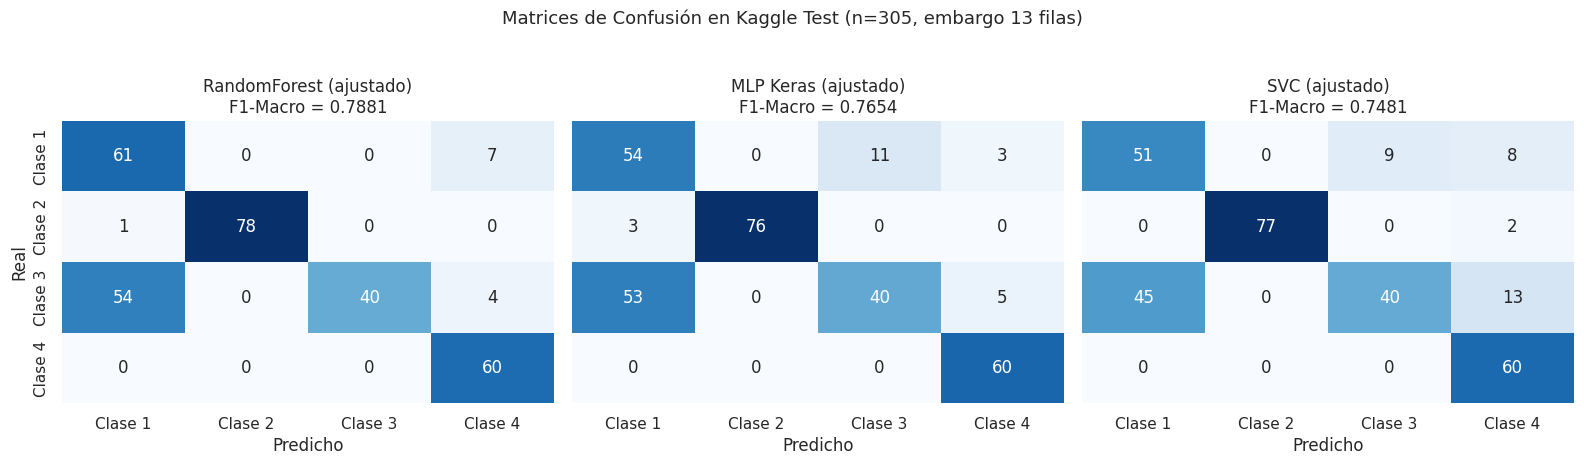

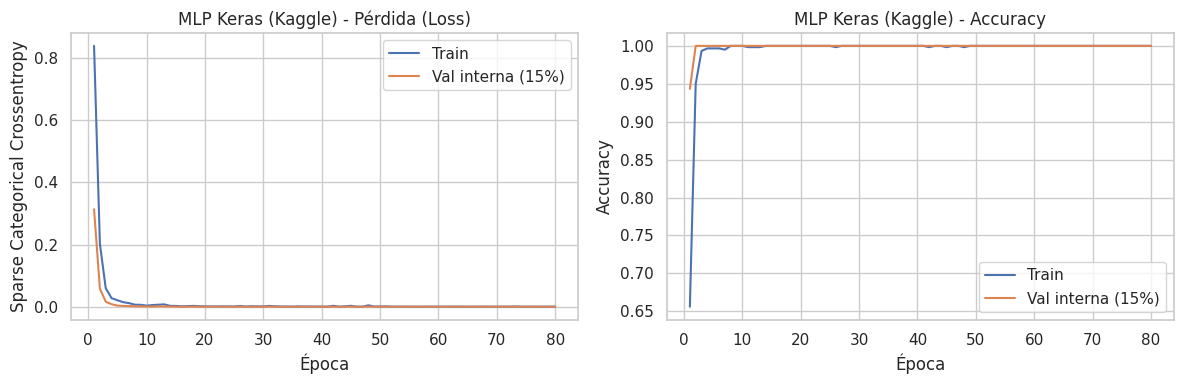

--- Reporte por clase del mejor modelo en Kaggle Test: RandomForest (ajustado) ---
              precision    recall  f1-score   support

     Clase 1     0.5259    0.8971    0.6630        68
     Clase 2     1.0000    0.9873    0.9936        79
     Clase 3     1.0000    0.4082    0.5797        98
     Clase 4     0.8451    1.0000    0.9160        60

    accuracy                         0.7836       305
   macro avg     0.8427    0.8231    0.7881       305
weighted avg     0.8638    0.7836    0.7717       305



In [ ]:
# Gráficos finales (matrices de confusión + history MLP) y guardado del modelo
from sklearn.metrics import classification_report, confusion_matrix

etiquetas_k = [f"Clase {c}" for c in le_kaggle.classes_]
orden_modelos = df_kaggle_test["Modelo"].tolist()

# Matrices de confusión de los 3 enfoques en kaggle_test
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, nombre in zip(axes, orden_modelos):
    cm = confusion_matrix(y_k_test, preds_kaggle_test[nombre])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=etiquetas_k, yticklabels=etiquetas_k, ax=ax,
    )
    f1_val = df_kaggle_test.loc[df_kaggle_test["Modelo"] == nombre, "F1_Macro"].values[0]
    ax.set_title(f"{nombre}\nF1-Macro = {f1_val:.4f}")
    ax.set_xlabel("Predicho")
axes[0].set_ylabel("Real")

plt.suptitle("Matrices de Confusión en Kaggle Test (n=305, embargo 13 filas)", y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "kaggle_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Curvas de aprendizaje del MLP Keras (train vs validación interna de EarlyStopping)
hist = history_mlp_k_final.history
epocas = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epocas, hist["loss"], label="Train")
axes[0].plot(epocas, hist["val_loss"], label="Val interna (15%)")
axes[0].set_title("MLP Keras (Kaggle) - Pérdida (Loss)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Sparse Categorical Crossentropy")
axes[0].legend()

axes[1].plot(epocas, hist["accuracy"], label="Train")
axes[1].plot(epocas, hist["val_accuracy"], label="Val interna (15%)")
axes[1].set_title("MLP Keras (Kaggle) - Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "kaggle_mlp_history.png", dpi=150, bbox_inches="tight")
plt.show()

# Reporte detallado y matriz de confusión del mejor modelo en Kaggle Test
mejor_nombre_k = orden_modelos[0]
print(f"--- Reporte por clase del mejor modelo en Kaggle Test: {mejor_nombre_k} ---")
print(classification_report(y_k_test, preds_kaggle_test[mejor_nombre_k], target_names=etiquetas_k, digits=4))

In [31]:
# exportación del mejor modelo de Kaggle
ruta_modelo_k = MODELS_DIR / "best_model_kaggle.joblib"
joblib.dump(
    {"modelo": modelos_finales_kaggle[mejor_nombre_k], "label_encoder": le_kaggle, "features": feature_cols_k},
    ruta_modelo_k,
)
print(f"Modelo guardado en: {ruta_modelo_k}")

Modelo guardado en: /home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/models/best_model_kaggle.joblib


----------------------------------------------------------------------------------------------------------------------------------------------

BLOQUE B: GITHUB

Preparamos los datos: Separación X/y (sin metadatos), codificación y StratifiedKFold(4)

In [32]:
# configuración de features y target para el dataset de GitHub (sin metadatos)
meta_cols_g = ["trip_id", "event_id", "target"]
feature_cols_g = [c for c in github_df.columns if c not in meta_cols_g]

X_g = github_df[feature_cols_g].copy()
le_github = LabelEncoder()
y_g = le_github.fit_transform(github_df["target"])

# 4 folds porque la clase minoritaria (troca_faixa_esquerda_agressiva) tiene 4 eventos
cv_github = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

# Contenedores compartidos para los 3 enfoques en GitHub
resultados_github_cv = []
oof_preds_github = {}

# confirmar 15 features, codificación y presencia de las 7 clases en cada fold
print(f"X_g shape: {X_g.shape} | Features ({len(feature_cols_g)}): {feature_cols_g}")
print("\nClases codificadas:")
for idx, clase in enumerate(le_github.classes_):
    print(f"  {idx}: {clase} (n={(y_g == idx).sum()})")

print("\nDistribución de clases por fold de validación (4-Fold Stratified):")
for fold, (_, val_idx) in enumerate(cv_github.split(X_g, y_g), start=1):
    conteo = pd.Series(y_g[val_idx]).value_counts().sort_index().to_dict()
    print(f"  Fold {fold} (n={len(val_idx)}): {conteo} | clases presentes: {len(conteo)}")

X_g shape: (69, 15) | Features (15): ['duracion_sec', 'acc_mag_xy_mean', 'acc_mag_xy_std', 'acc_mag_xy_max', 'acc_z_mean', 'acc_z_std', 'acc_z_min', 'acc_z_max', 'gyro_z_std', 'gyro_z_min', 'gyro_z_max', 'gyro_z_abs_mean', 'gyro_z_net_rad', 'gyro_mag_xy_mean', 'gyro_mag_xy_max']

Clases codificadas:
  0: aceleracao_agressiva (n=12)
  1: curva_direita_agressiva (n=11)
  2: curva_esquerda_agressiva (n=11)
  3: evento_nao_agressivo (n=14)
  4: freada_agressiva (n=12)
  5: troca_faixa_direita_agressiva (n=5)
  6: troca_faixa_esquerda_agressiva (n=4)

Distribución de clases por fold de validación (4-Fold Stratified):
  Fold 1 (n=18): {0: 3, 1: 3, 2: 2, 3: 4, 4: 3, 5: 2, 6: 1} | clases presentes: 7
  Fold 2 (n=17): {0: 3, 1: 2, 2: 3, 3: 4, 4: 3, 5: 1, 6: 1} | clases presentes: 7
  Fold 3 (n=17): {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 1, 6: 1} | clases presentes: 7
  Fold 4 (n=17): {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 1, 6: 1} | clases presentes: 7


todo impecable, vemos las 7 clases presentes en cada fold, y ademas se extrajieron los targets.

Modelo 1 en GitHub — SVC

In [33]:
from sklearn.model_selection import cross_val_predict

# Pipeline base
pipe_svc_g = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=SEED),
)

res_svc_g_base = evaluar_cv_sklearn("SVC (base)", pipe_svc_g, X_g, y_g, cv_github)

# Búsqueda acotada (22 combinaciones x 4 folds = 88 ajustes; incluye balanceo de clases)
param_grid_svc_g = [
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.5, 1, 5, 10],
        "svc__gamma": ["scale", 0.1],
        "svc__class_weight": [None, "balanced"],
    },
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10],
        "svc__class_weight": [None, "balanced"],
    },
]

# GridSearchCV para ajustar hiperparámetros del SVC en GitHub
grid_svc_g = GridSearchCV(
    estimator=pipe_svc_g,
    param_grid=param_grid_svc_g,
    cv=cv_github,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
)
grid_svc_g.fit(X_g, y_g)

best_svc_g = grid_svc_g.best_estimator_
res_svc_g_tuned = evaluar_cv_sklearn("SVC (ajustado)", best_svc_g, X_g, y_g, cv_github)

# Guardamos métricas y predicciones out-of-fold (sin duplicar si se re-ejecuta)
resultados_github_cv = [r for r in resultados_github_cv if not r["Modelo"].startswith("SVC")]
resultados_github_cv.append(res_svc_g_tuned)
oof_preds_github["SVC (ajustado)"] = cross_val_predict(
    best_svc_g, X_g, y_g, cv=cv_github, n_jobs=-1
)

# Reporte de resultados
print(f"Mejores hiperparámetros SVC (GitHub): {grid_svc_g.best_params_}")
display(pd.DataFrame([res_svc_g_base, res_svc_g_tuned]).round(4))

/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier

Mejores hiperparámetros SVC (GitHub): {'svc__C': 10, 'svc__class_weight': None, 'svc__kernel': 'linear'}


/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/

,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,SVC (base),0.8693,0.7988,0.8304,0.7991,0.0747,0.9793,0.0690
1,SVC (ajustado),0.9126,0.9048,0.9107,0.9010,0.0679,0.9917,0.0107


El ajuste de hiperparámetros produjo una mejora considerable respecto de la configuración inicial. La mejor configuración utilizó un kernel lineal y C=10, sin necesidad de aplicar ponderaciones para compensar el desbalance entre clases.

El ajuste permitió mejorar el Macro-F1 en 10,19 puntos porcentuales. A diferencia de Kaggle, donde se seleccionó un kernel no lineal, en GitHub la configuración lineal obtuvo mejores resultados.

Modelo 2 en GitHub — MLP en tf.keras

In [34]:
# evaluación de un MLP en validación cruzada para el dataset de GitHub, recolectando predicciones OOF (out-of-fold) y métricas promedio por fold
def evaluar_cv_keras_github(nombre, X, y, cv, unidades=(32, 16), dropout=0.2,
                            lr=3e-3, batch_size=8, epochs=100):
    n_clases = len(np.unique(y))
    oof_pred = np.zeros(len(y), dtype=int)
    accs, precs, recs, f1s, aucs, tiempos, histories = [], [], [], [], [], [], []
    
    # Iteramos sobre cada fold de validación
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + fold)
        # Escalado de features (StandardScaler) ajustado solo con el fold de entrenamiento
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X.iloc[tr_idx])
        X_val = scaler.transform(X.iloc[val_idx])
        y_tr, y_val = y[tr_idx], y[val_idx]

        modelo = construir_mlp(X.shape[1], n_clases, unidades=unidades, dropout=dropout, lr=lr)
        
        t0 = time.perf_counter() # Medimos el tiempo de ajuste del modelo
        hist = modelo.fit(
            X_tr, y_tr,
            epochs=epochs,
            batch_size=batch_size,
            verbose=0,
        )
        tiempos.append(time.perf_counter() - t0)
        histories.append(hist.history)
        # Evaluación estricta sobre el fold de validación completamente virgen
        y_prob = modelo(X_val, training=False).numpy()
        y_pred = y_prob.argmax(axis=1)
        oof_pred[val_idx] = y_pred
        
        # Calculamos métricas para este fold
        accs.append(accuracy_score(y_val, y_pred))
        precs.append(precision_score(y_val, y_pred, average="macro", zero_division=0))
        recs.append(recall_score(y_val, y_pred, average="macro", zero_division=0))
        f1s.append(f1_score(y_val, y_pred, average="macro", zero_division=0))
        aucs.append(roc_auc_score(y_val, y_prob, multi_class="ovr", average="macro"))

    resumen = {
        "Modelo": nombre,
        "Accuracy": np.mean(accs),
        "Precision_Macro": np.mean(precs),
        "Recall_Macro": np.mean(recs),
        "F1_Macro": np.mean(f1s),
        "F1_Std": np.std(f1s),
        "ROC_AUC_OvR": np.mean(aucs),
        "Fit_Time_s": np.mean(tiempos),
    }
    return resumen, oof_pred, histories

# Búsqueda acotada pensada para n=69 (capas chicas)
configs_mlp_g = [
    {"nombre": "MLP (16, lr=3e-3, ep=100)", "unidades": (16,), "dropout": 0.2, "lr": 3e-3, "epochs": 100, "batch_size": 8},
    {"nombre": "MLP (32-16, lr=3e-3, ep=100)", "unidades": (32, 16), "dropout": 0.2, "lr": 3e-3, "epochs": 100, "batch_size": 8},
    {"nombre": "MLP (32-16, lr=5e-3, ep=120)", "unidades": (32, 16), "dropout": 0.2, "lr": 5e-3, "epochs": 120, "batch_size": 8},
]

# se crean contenedores para resultados, predicciones OOF y histories de entrenamiento
res_mlp_g_lista = []
oofs_mlp_g = {}
histories_mlp_g = {}

# Iteramos sobre cada configuración de MLP y evaluamos con validación cruzada
for cfg in configs_mlp_g:
    res, oof, hists = evaluar_cv_keras_github(
        cfg["nombre"], X_g, y_g, cv_github,
        unidades=cfg["unidades"], dropout=cfg["dropout"],
        lr=cfg["lr"], batch_size=cfg["batch_size"], epochs=cfg["epochs"],
    )
    res_mlp_g_lista.append(res)
    oofs_mlp_g[cfg["nombre"]] = oof
    histories_mlp_g[cfg["nombre"]] = hists

# Selección del mejor MLP según F1_Macro y agregamos al contenedor de resultados
df_mlp_g = pd.DataFrame(res_mlp_g_lista)
idx_mejor_g = df_mlp_g["F1_Macro"].idxmax()
best_mlp_g_cfg = configs_mlp_g[idx_mejor_g]
best_mlp_g_res = dict(res_mlp_g_lista[idx_mejor_g], Modelo="MLP Keras (ajustado)")

# Guardamos métricas y predicciones OOF (sin duplicar si se re-ejecuta)
resultados_github_cv = [r for r in resultados_github_cv if not r["Modelo"].startswith("MLP")]
resultados_github_cv.append(best_mlp_g_res)
oof_preds_github["MLP Keras (ajustado)"] = oofs_mlp_g[best_mlp_g_cfg["nombre"]]

print(f"Mejor configuración MLP (GitHub): {best_mlp_g_cfg}")
display(df_mlp_g.round(4))

Mejor configuración MLP (GitHub): {'nombre': 'MLP (16, lr=3e-3, ep=100)', 'unidades': (16,), 'dropout': 0.2, 'lr': 0.003, 'epochs': 100, 'batch_size': 8}


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,"MLP (16, lr=3e-3, ep=100)",0.9126,0.8542,0.8839,0.8558,0.0912,0.9885,7.7890
1,"MLP (32-16, lr=3e-3, ep=100)",0.8987,0.8470,0.8720,0.8411,0.0801,0.9913,7.8750
2,"MLP (32-16, lr=5e-3, ep=120)",0.9126,0.8512,0.8839,0.8537,0.0932,0.9944,9.2507


La mejor configuración correspondió a la arquitectura más pequeña, compuesta por una única capa oculta de 16 neuronas, una tasa de aprendizaje de 0,003 y 100 épocas de entrenamiento.

El mejor desempeño de la arquitectura pequeña sugiere que, ante un conjunto de datos tan reducido, aumentar la cantidad de capas y neuronas puede resultar innecesario e incrementar el riesgo de sobreajuste.

Si bien el MLP obtuvo exactamente el mismo accuracy que SVC (0,9126), su Macro-F1 fue 4,52 puntos porcentuales inferior. Esta diferencia evidencia la importancia de considerar métricas que otorguen el mismo peso a todas las clases, especialmente en datasets desbalanceados.

Modelo 3 en GitHub — RandomForestClassifier

In [35]:
# cargamos el RandomForest base y ajustado para el dataset de GitHub
rf_base_g = RandomForestClassifier(random_state=SEED)
res_rf_g_base = evaluar_cv_sklearn("RandomForest (base)", rf_base_g, X_g, y_g, cv_github)

# Búsqueda acotada (32 combinaciones x 4 folds = 128 ajustes)
# min_samples_leaf llega hasta 2 porque la clase minoritaria tiene solo 3 muestras en train por fold
param_grid_rf_g = {
    "n_estimators": [100, 200],
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 6],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"],
}

grid_rf_g = GridSearchCV(
    estimator=rf_base_g,
    param_grid=param_grid_rf_g,
    cv=cv_github,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
)
grid_rf_g.fit(X_g, y_g)

best_rf_g = grid_rf_g.best_estimator_
res_rf_g_tuned = evaluar_cv_sklearn("RandomForest (ajustado)", best_rf_g, X_g, y_g, cv_github)

# Guardamos métricas y predicciones OOF (sin duplicar si se re-ejecuta)
resultados_github_cv = [r for r in resultados_github_cv if not r["Modelo"].startswith("RandomForest")]
resultados_github_cv.append(res_rf_g_tuned)
oof_preds_github["RandomForest (ajustado)"] = cross_val_predict(
    best_rf_g, X_g, y_g, cv=cv_github, n_jobs=-1
)

# Reporte individual
print(f"Mejores hiperparámetros RandomForest (GitHub): {grid_rf_g.best_params_}")
display(pd.DataFrame([res_rf_g_base, res_rf_g_tuned]).round(4))

/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Mejores hiperparámetros RandomForest (GitHub): {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,RandomForest (base),0.9126,0.8696,0.8839,0.8659,0.1113,0.9932,0.3082
1,RandomForest (ajustado),0.9273,0.9214,0.9196,0.9117,0.0708,0.9920,0.3989


In [36]:
# tabla comparativa de los 3 enfoques en GitHub (4-Fold CV)
print("\n--- Resumen Comparativo en 4-Fold CV (GitHub Events, n=69) ---")
df_github_cv = (
    pd.DataFrame(resultados_github_cv)
    .sort_values("F1_Macro", ascending=False)
    .reset_index(drop=True)
)
display(df_github_cv.round(4))


--- Resumen Comparativo en 4-Fold CV (GitHub Events, n=69) ---


,Modelo,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Std,ROC_AUC_OvR,Fit_Time_s
0,RandomForest (ajustado),0.9273,0.9214,0.9196,0.9117,0.0708,0.9920,0.3989
1,SVC (ajustado),0.9126,0.9048,0.9107,0.9010,0.0679,0.9917,0.0107
2,MLP Keras (ajustado),0.9126,0.8542,0.8839,0.8558,0.0912,0.9885,7.7890


Random Forest obtuvo el mejor desempeño en las métricas de clasificación, seguido muy de cerca por SVC. Sin embargo, la diferencia de Macro-F1 entre ambos es de apenas 1,07 puntos porcentuales, considerablemente inferior a la variabilidad entre particiones. Por lo tanto, no existe evidencia suficiente para afirmar una superioridad concluyente.

Respecto al costo computacional, SVC fue aproximadamente 37 veces más rápido que Random Forest y 728 veces más rápido que MLP, además de presentar la menor variabilidad entre particiones.

Matrices de confusión OOF, importancia de features y exportación:

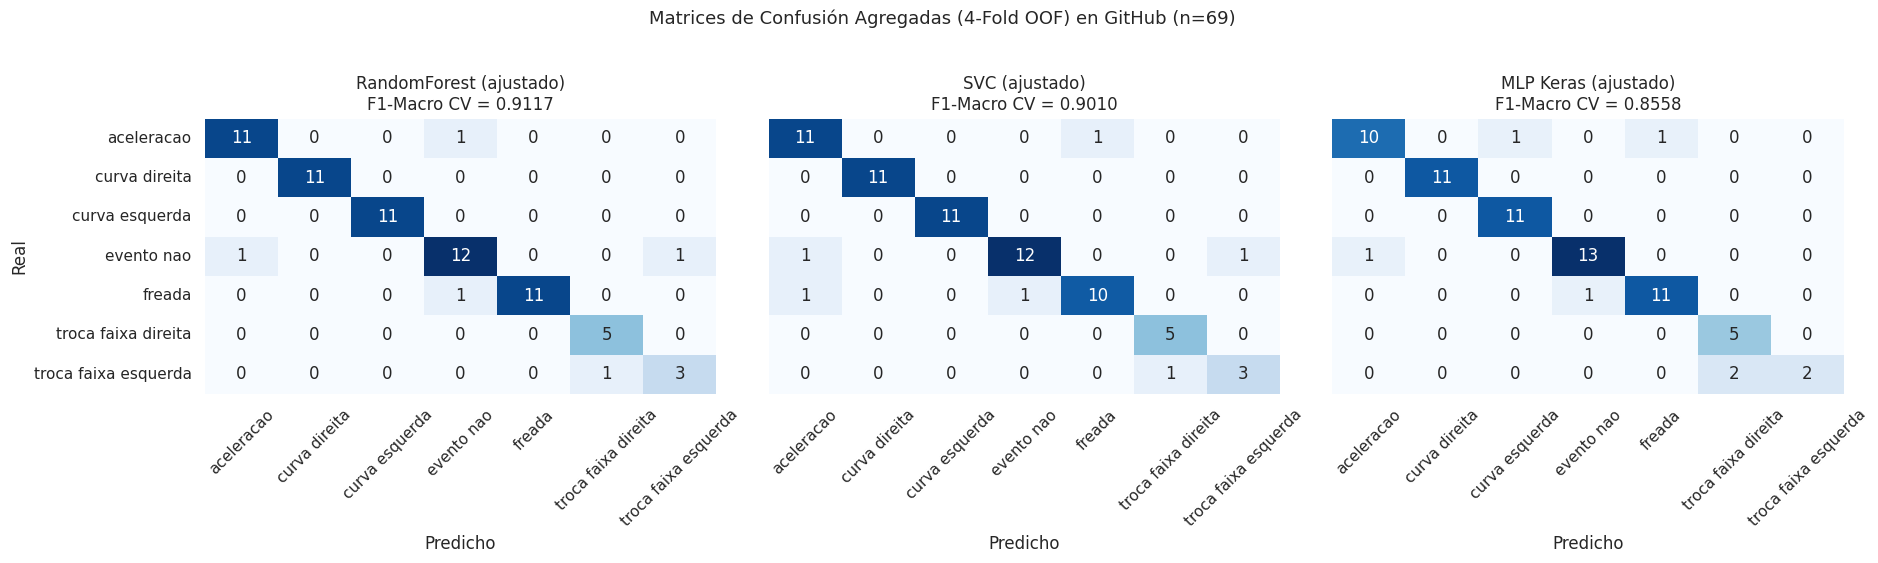

--- Reporte OOF por clase del mejor modelo en GitHub: RandomForest (ajustado) ---
                                precision    recall  f1-score   support

          aceleracao_agressiva     0.9167    0.9167    0.9167        12
       curva_direita_agressiva     1.0000    1.0000    1.0000        11
      curva_esquerda_agressiva     1.0000    1.0000    1.0000        11
          evento_nao_agressivo     0.8571    0.8571    0.8571        14
              freada_agressiva     1.0000    0.9167    0.9565        12
 troca_faixa_direita_agressiva     0.8333    1.0000    0.9091         5
troca_faixa_esquerda_agressiva     0.7500    0.7500    0.7500         4

                      accuracy                         0.9275        69
                     macro avg     0.9082    0.9201    0.9128        69
                  weighted avg     0.9300    0.9275    0.9279        69



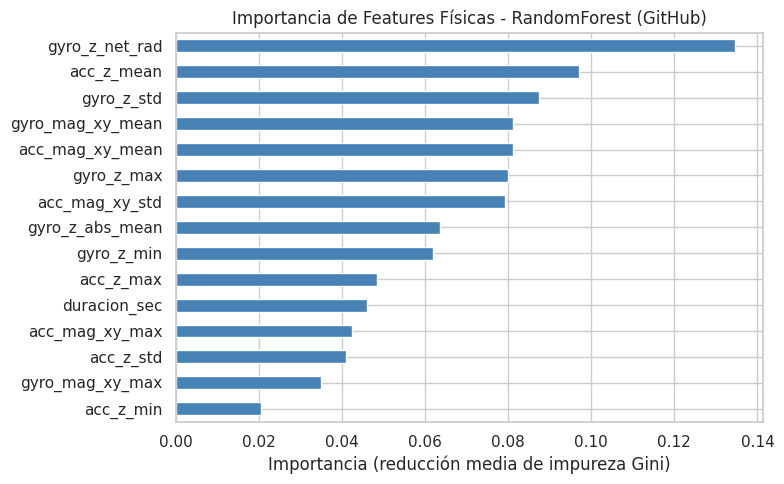

Modelo guardado en: /home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/models/best_model_github.joblib


In [ ]:
# Etiquetas cortas para que los ejes de los heatmaps sean legibles
etiquetas_g = [
    c.replace("_agressiva", "").replace("_agressivo", "").replace("_", " ")
    for c in le_github.classes_
]
orden_modelos_g = df_github_cv["Modelo"].tolist()

# Matrices de confusión agregadas (predicciones out-of-fold sobre los 69 eventos)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True)
for ax, nombre in zip(axes, orden_modelos_g):
    cm = confusion_matrix(y_g, oof_preds_github[nombre])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=etiquetas_g, yticklabels=etiquetas_g, ax=ax,
    )
    f1_val = df_github_cv.loc[df_github_cv["Modelo"] == nombre, "F1_Macro"].values[0]
    ax.set_title(f"{nombre}\nF1-Macro CV = {f1_val:.4f}")
    ax.set_xlabel("Predicho")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Real")

plt.suptitle("Matrices de Confusión Agregadas (4-Fold OOF) en GitHub (n=69)", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "github_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Reporte detallado por clase del ganador en GitHub
mejor_nombre_g = orden_modelos_g[0]
print(f"--- Reporte OOF por clase del mejor modelo en GitHub: {mejor_nombre_g} ---")
print(classification_report(y_g, oof_preds_github[mejor_nombre_g], target_names=le_github.classes_, digits=4))

# Importancia de features físicas del RandomForest ajustado (ya reentrenado sobre los 69 eventos)
importancias = pd.Series(best_rf_g.feature_importances_, index=feature_cols_g).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importancias.plot(kind="barh", color="steelblue", ax=ax)
ax.set_title("Importancia de Features Físicas - RandomForest (GitHub)")
ax.set_xlabel("Importancia (reducción media de impureza Gini)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "github_rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# Exportación del mejor modelo de GitHub
modelos_finales_github = {
    "RandomForest (ajustado)": best_rf_g,
    "SVC (ajustado)": best_svc_g,
}
ruta_modelo_g = MODELS_DIR / "best_model_github.joblib"
joblib.dump(
    {"modelo": modelos_finales_github[mejor_nombre_g], "label_encoder": le_github, "features": feature_cols_g},
    ruta_modelo_g,
)
print(f"Modelo guardado en: {ruta_modelo_g}")